In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from arvore_decisao import ArvoreDecisao
from funcoes_aux_proj_apr_supervisionada import extrair_atributos, imprimir_arvore, obter_nomes_atributos
import matplotlib.pyplot as plt
# É usado a seed 555 para o uso do kmeans de forma a manter-se coerente com o enunciado da entrega passada

df = pd.read_pickle('Xsup.pkl')

# RETIRAR DEPOIS NA ENTREGA DO PROJETO
print(df.columns.tolist())
print(sorted(df['Patient_ID'].unique()))
print(df['Patient_ID'].value_counts().sort_index())

['Skeleton_Sequence', 'Exercise_Id', 'Patient_ID', 'Compensação_Ombro', 'Compensação_Tronco', 'Compensação_Cabeça']
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
Patient_ID
1     70
2     70
3     70
4     70
5     70
6     70
7     70
8     70
9     70
10    70
11    70
12    70
13    70
14    70
15    70
16    70
17    70
18    69
Name: count, dtype: int64


## Parte II - Árvores de Decisão

#### R.3b)

In [2]:
filtro_p4 = df['Patient_ID'] == 4

mapa = {'E1': 0, 'E2': 1, 'E3': 2, 'E4': 3, 'E5': 4}

seqs = df.loc[filtro_p4, 'Skeleton_Sequence'].to_list()
y    = df.loc[filtro_p4, 'Exercise_Id'].map(mapa).to_numpy()

n_test = int(round(0.2 * len(seqs)))

seqs_treino, seqs_teste = seqs[:-n_test], seqs[-n_test:]
y_treino,    y_teste    = y[:-n_test],    y[-n_test:]

#### R.3c)

In [3]:
def construir_X(seqs):
    atributos = []
    for seq in seqs:                            # uma sequência de cada vez
        atributos.append(extrair_atributos(seq))
    return np.array(atributos)                  # (n_seqs × d)

Xtrain = construir_X(seqs_treino)
Xtest  = construir_X(seqs_teste)

print(Xtrain.shape, Xtest.shape)

(56, 268) (14, 268)


#### R3.d)

In [4]:
def calcular_metricas(y_verdadeiro, y_previsto):
    P = confusion_matrix(y_verdadeiro, y_previsto, labels=[0, 1, 2, 3, 4])
    bacc = balanced_accuracy_score(y_verdadeiro, y_previsto)
    return P, bacc

#### R4.a)

In [5]:
arvores = {}          # guardar as árvores treinadas para a R4.b e R4.c
resultados = []

for d in range(1, 6):
    arv = ArvoreDecisao(profundidade_maxima=d)
    arv.fit(Xtrain, y_treino)

    _, bacc_treino = calcular_metricas(y_treino, arv.predict(Xtrain))
    _, bacc_teste  = calcular_metricas(y_teste,  arv.predict(Xtest))

    arvores[d] = arv
    resultados.append((d, bacc_treino, bacc_teste))
    print(f"Profundidade {d}: treino = {bacc_treino:.3f} | teste = {bacc_teste:.3f}")

Profundidade 1: treino = 0.389 | teste = 0.400
Profundidade 2: treino = 0.749 | teste = 0.760
Profundidade 3: treino = 0.967 | teste = 0.910
Profundidade 4: treino = 1.000 | teste = 0.910
Profundidade 5: treino = 1.000 | teste = 0.910


#### R4.b)

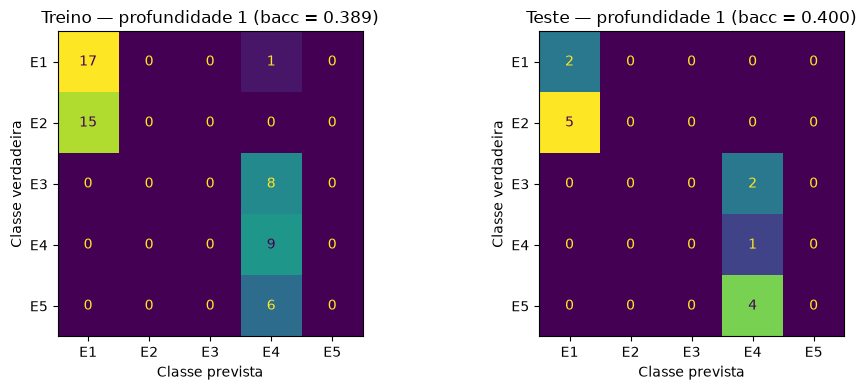

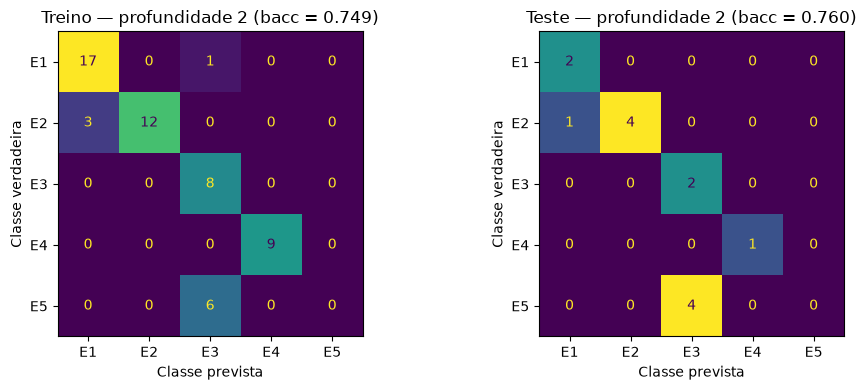

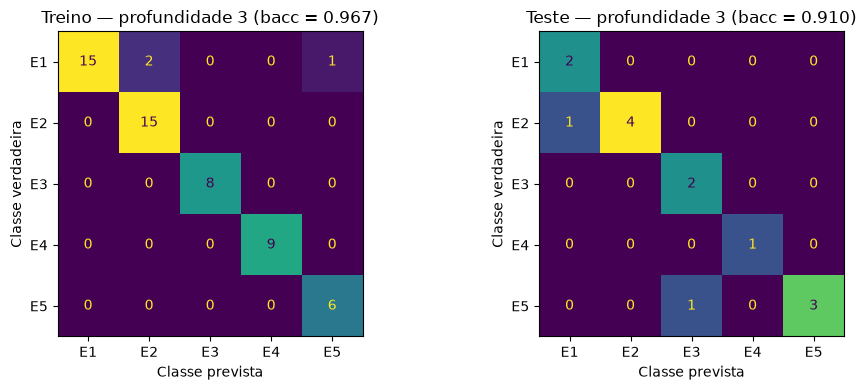

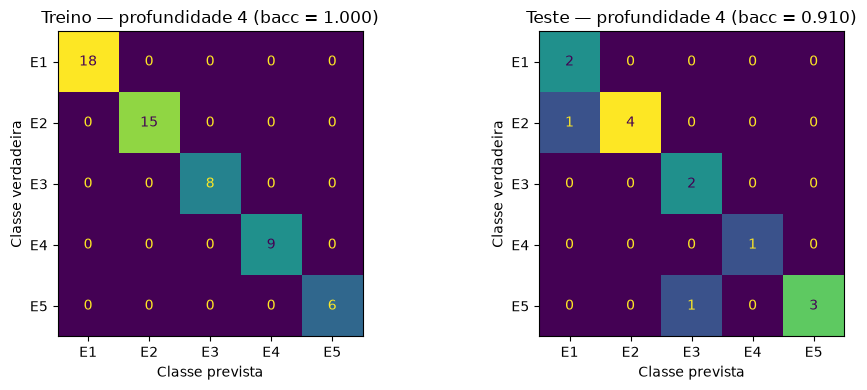

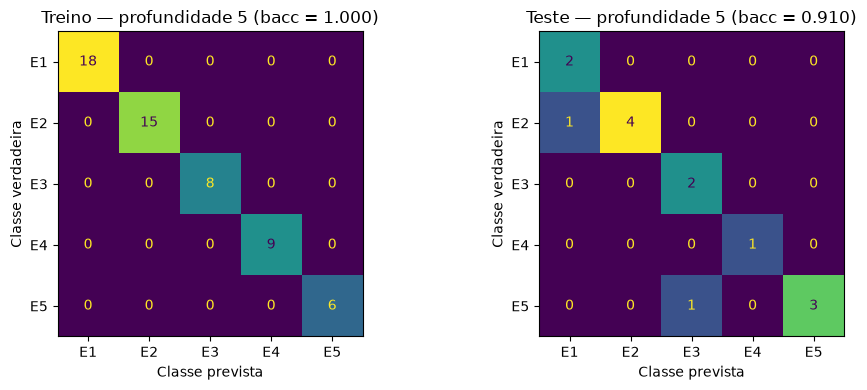

In [ ]:
nomes_classes = ['E1', 'E2', 'E3', 'E4', 'E5']

for d, arv in arvores.items():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, (nome, X_, y_) in zip(axes, [('Treino', Xtrain, y_treino),('Teste',  Xtest,  y_teste)]):

        P, bacc = calcular_metricas(y_, arv.predict(X_))
        ConfusionMatrixDisplay(P, display_labels=nomes_classes).plot(ax=ax, colorbar=False)
        ax.set_title(f'{nome} — profundidade {d} (bacc = {bacc:.3f})')
        ax.set_xlabel('Classe prevista')
        ax.set_ylabel('Classe verdadeira')

    fig.tight_layout()
    #fig.savefig(f'Figuras_R4/R4b_prof{d}.jpg', dpi=150)
    plt.show()

#### R4.c)

In [6]:
nomes = obter_nomes_atributos()                    # 268 nomes, pela ordem das colunas de Xtrain
idx_to_class = {v: k for k, v in mapa.items()}     # {0: 'E1', 1: 'E2', ...}

arvore_4 = arvores[4]
imprimir_arvore(arvore_4.raiz, nomes_atributos=nomes, idx_to_class=idx_to_class)

├── [cotovelo_esquerdo_desvio_padrao_vel_y <= 0.006416]
  [Verdadeiro]
    ├── [amplitude_movimento_joelho_esquerdo <= 11.538988]
      [Verdadeiro]
        ├── [cotovelo_esquerdo_desvio_padrao_vel_x <= 0.004645]
          [Verdadeiro]
            ├── [orelha_esquerda_media_vel_x <= -0.000051]
              [Verdadeiro]
                └── Folha: E1
              [Falso]
                └── Folha: E2
          [Falso]
            └── Folha: E1
      [Falso]
        └── Folha: E2
  [Falso]
    ├── [nariz_desvio_padrao_vel_y <= 0.010464]
      [Verdadeiro]
        ├── [punho_direito_desvio_padrao_vel_y <= 0.012200]
          [Verdadeiro]
            ├── [ombro_esquerdo_media_vel_y <= -0.001206]
              [Verdadeiro]
                └── Folha: E1
              [Falso]
                └── Folha: E5
          [Falso]
            └── Folha: E3
      [Falso]
        └── Folha: E4


## Parte III - Naive Bayes

### Kmeans & Inicialização do 6

In [7]:
def kminit(X, K, flag):
    N = X.shape[0]
    C = []
    first_idx = np.random.randint(N)
    C.append(X[first_idx])

    if flag == 0:
        idx = np.random.choice(N, K - 1, replace=False)
        while first_idx in idx:  # caso raro --> repetiu o primeiro
            idx = np.random.choice(N, K - 1, replace=False)
        C.extend(X[idx])

    else:  # k-means++
        for _ in range(K - 1):
            C_current = np.array(C)
            M = np.zeros((N, len(C_current)))

            # distância ao quadrado de cada pose a cada centroide já escolhido
            for k in range(len(C_current)):
                M[:, k] = np.sum((X - C_current[k])**2, axis=1)

            # distância de cada pose ao centroide MAIS PRÓXIMO: (N,)
            min_sq_dist = np.min(M, axis=1)

            # probabilidade
            prob = min_sq_dist / np.sum(min_sq_dist)

            new_idx = np.random.choice(N, p=prob)
            C.append(X[new_idx])

    return np.array(C)

In [8]:
def kmeans_cost(X, C, s):
    assigned_centroids = C[s]

    # distância euclidiana de cada pose ao seu centroide: (N,)
    sq_dist = np.sum((X - assigned_centroids)**2, axis=1)

    total_cost = np.sum(sq_dist)

    return total_cost


In [9]:
def atribuir(X, C):
    K = C.shape[0]
    M = np.zeros((X.shape[0], K))

    for k in range(K):
        M[:, k] = np.sum((X - C[k])**2, axis=1)  
    return np.argmin(M, axis=1)  # índice do centróide mais próximo de cada pose

In [10]:
def kmeans(X, K, flag):
    # Aplica o algoritmo k-means à matriz de dados X.
    C = kminit(X, K, flag)
    prev_cost = np.inf

    while True:
        s = atribuir(X, C)  

        total_cost = kmeans_cost(X, C, s)

        # Comparação dos custos
        if prev_cost - total_cost < 1e-6:
            break
        prev_cost = total_cost

        # Atualização dos centróides
        for k in range(K):
            cluster = X[s == k]
            if len(cluster) > 0:
                C[k] = np.mean(cluster, axis=0)

    return C, s

In [11]:
def histograma_poses(seq, C, scaler):
    seq_norm = scaler.transform(seq)       # mesma normalização usada no k-means
    s = atribuir(seq_norm, C)              
    K = C.shape[0]
    h, _ = np.histogram(s, bins=np.arange(K + 1))
    return h / len(s)                      

In [ ]:
# poses de todas as sequências de TREINO
X_tr_poses = np.concatenate(seqs_treino)

scaler_bop = StandardScaler()
X_tr_norm = scaler_bop.fit_transform(X_tr_poses)

[0. 0. 1. 0. 0.] (5,) 1.0


In [15]:
def bag_of_poses(seqs, C, scaler):
    # seqs: coleção de sequências (cada uma T x 66)
    # devolve: (n_seq, K) um histograma por linha
    return np.array([histograma_poses(seq, C, scaler) for seq in seqs])

### R6.a)

In [19]:
resultados_bop = []

for K in [2, 5, 10, 15]:
    np.random.seed(555)                          
    C, _ = kmeans(X_tr_norm, K, 1)      

    H_tr = bag_of_poses(seqs_treino, C, scaler_bop)   #    histogramas (56 × K)
    H_te = bag_of_poses(seqs_teste,  C, scaler_bop)   #    histogramas (14 × K)

    nb = GaussianNB()                            # classificador
    nb.fit(H_tr, y_treino)

    P_tr, bacc_tr = calcular_metricas(y_treino, nb.predict(H_tr))
    P_te, bacc_te = calcular_metricas(y_teste,  nb.predict(H_te))

    resultados_bop.append((K, bacc_tr, bacc_te))
    print(f"K = {K:2d}: treino = {bacc_tr:.3f} | teste = {bacc_te:.3f}")
    print(P_te)

K =  2: treino = 0.400 | teste = 0.400
[[2 0 0 0 0]
 [5 0 0 0 0]
 [2 0 0 0 0]
 [0 0 0 1 0]
 [4 0 0 0 0]]
K =  5: treino = 0.811 | teste = 0.900
[[1 1 0 0 0]
 [0 5 0 0 0]
 [0 0 2 0 0]
 [0 0 0 1 0]
 [0 0 0 0 4]]
K = 10: treino = 0.811 | teste = 0.800
[[0 2 0 0 0]
 [0 5 0 0 0]
 [0 0 2 0 0]
 [0 0 0 1 0]
 [0 0 0 0 4]]
K = 15: treino = 0.911 | teste = 0.800
[[0 2 0 0 0]
 [0 5 0 0 0]
 [0 0 2 0 0]
 [0 0 0 1 0]
 [0 0 0 0 4]]


#### Extra - visualização do histograma por exercicio

In [ ]:
np.random.seed(555)
C_ex, _ = kmeans(X_tr_norm,5,1)
H_tr_ex = bag_of_poses(seqs_treino, C_ex, scaler_bop)
print(H_tr_ex.shape)   # deve dar (56, 5)

# histograma médio de cada exercício
for e, nome in enumerate(['E1', 'E2', 'E3', 'E4', 'E5']):
    print(nome, H_tr_ex[y_treino == e].mean(axis=0).round(2))

(56, 5)
E1 [0.   0.   0.98 0.02 0.  ]
E2 [0. 0. 1. 0. 0.]
E3 [0.   0.03 0.48 0.48 0.  ]
E4 [0.21 0.25 0.39 0.01 0.15]
E5 [0. 1. 0. 0. 0.]


### R6.b)

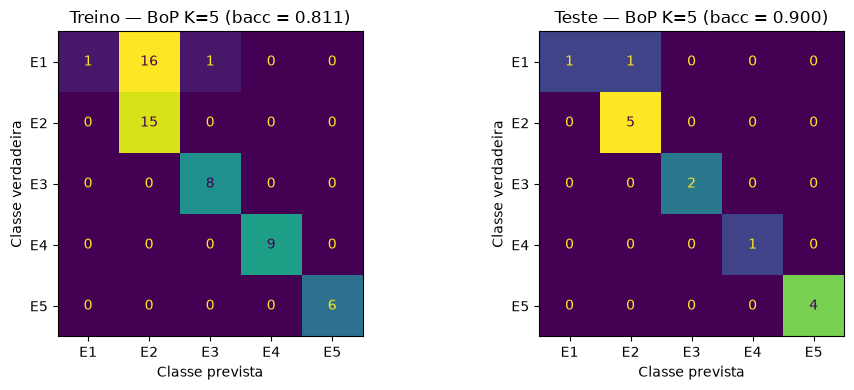

In [ ]:
K_escolhido = 5

np.random.seed(555)
C_5, _ = kmeans(X_tr_norm, K_escolhido, 1)
H_tr_5 = bag_of_poses(seqs_treino, C_5, scaler_bop)
H_te_5 = bag_of_poses(seqs_teste,  C_5, scaler_bop)

nb_bop = GaussianNB()
nb_bop.fit(H_tr_5, y_treino)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, H_, y_) in zip(axes, [('Treino', H_tr_5, y_treino), ('Teste', H_te_5, y_teste)]):
    P, bacc = calcular_metricas(y_, nb_bop.predict(H_))
    ConfusionMatrixDisplay(P, display_labels=nomes_classes).plot(ax=ax, colorbar=False)
    ax.set_title(f'{nome} — BoP K={K_escolhido} (bacc = {bacc:.3f})')
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe verdadeira')

fig.tight_layout()
#fig.savefig(f'R6b_K{K_escolhido}.jpg', dpi=150)
plt.show()